In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

In [5]:
mu0 = 4*np.pi*1e-7
sqrt_pi = np.sqrt(np.pi)

def bz_halfspace_center_circle_loop_time(times, sigma, r, I=1.):
    theta = np.sqrt(0.25*mu0*sigma / times)
    theta_r = theta*r

    hz = 3*np.exp(-theta_r**2)/(r*theta*sqrt_pi) + (1 - 3 / (2*theta_r**2))*erf(theta_r)
    hz *= I/(2*r)
    return hz*mu0


def bzdt_halfspace_center_circle_loop(times, sigma, r, I=1.):
    theta = np.sqrt(0.25*mu0*sigma / times)
    dhdt = 1./(mu0*sigma*r**3)*(3*erf(theta*r)-2*theta*r*(3+2*theta**2*r**2)*np.exp(-theta**2*r**2)/sqrt_pi)
    return dhdt*mu0


In [23]:
def lin_int(x_sample, x_out, dx=None):
    if dx is None:
        dx = x_sample[1] - x_sample[0]
    norm_x = (x_sample-x_out)/dx
    y = np.zeros_like(norm_x)
    y[np.abs(norm_x)<1] = 1 - np.abs(norm_x[np.abs(norm_x)<1])
    return y   

In [33]:
S1 = lambda x: 1 - (9/4)*x**2 * ( 1 - 2./9*x*(1 + 5/2*x*(1 - 2/5 * x)))
S2 = lambda x: -1/2*x*(1 - 11/6*x*(1 - 2/11*x*(1 + 5/2*x*(1-2/5*x))))

def lamontagne(x):
    phi   = x*0.
    xm2m1 = (-2 <= x)*(x < -1)
    xm1m0 = (-1 <= x)*(x < 0)
    x0p1  = (0 <= x)*(x <= 1)
    x1p2  = (1 < x)*(x <= 2)
    
    phi[xm2m1] = S2(-x[xm2m1]-1)
    phi[xm1m0] = S1(-x[xm1m0])
    phi[x0p1] = S1(x[x0p1])
    phi[x1p2] = S2(x[x1p2]-1)
    
    return phi

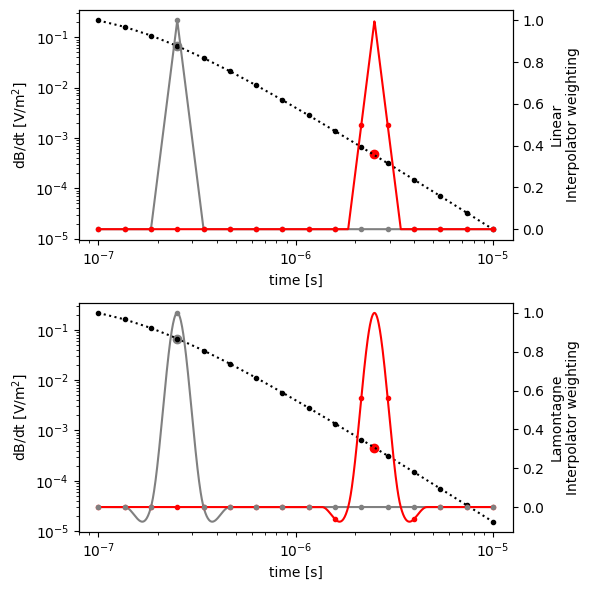

In [62]:
t = np.geomspace(1e-7, 1e-5, 16)
dbdt = bzdt_halfspace_center_circle_loop(t, 1e-2, 10)

logt = np.log10(t)
dLt = logt[1] - logt[0]

pnt1x = logt[3]
pnt2x = -5.6

lin6 =lin_int(logt, pnt1x)
lin5p5 =lin_int(logt, pnt2x)


pnt1 = lin6@dbdt
pnt2 = lin5p5@dbdt



logt_plot = np.linspace(-7, -5, 1000)

lin6_plot =lin_int(logt_plot, pnt2x, dLt)
linp5_plot =lin_int(logt_plot, pnt1x, dLt)





fig,axs = plt.subplots(2,1, figsize=(6, 6))
ax1 = axs[0]
ax2 = ax1.twinx()

ax2.semilogx(10**logt_plot, linp5_plot, 'gray')
ax2.semilogx(10**logt, lin6, '.', color='gray')
ax1.semilogx(10**pnt1x, pnt1, 'o', color='gray')



ax2.semilogx(10**logt_plot, lin6_plot, 'r-')
ax2.semilogx(10**logt, lin5p5, 'r.')
ax1.semilogx(10**pnt2x, pnt2, 'ro')

ax1.loglog(10**logt, dbdt, 'k:')
ax1.loglog(10**logt, dbdt, 'k.')

ax1.set_ylabel('dB/dt [V/m$^2$]')
ax2.set_ylabel('Linear\nInterpolator weighting')



lin6 = lamontagne((logt-pnt1x)/dLt)
lin5p5 = lamontagne((logt-pnt2x)/dLt)


pnt1 = lin6@dbdt
pnt2 = lin5p5@dbdt



lin6_plot = lamontagne((logt_plot-pnt2x)/dLt)
linp5_plot = lamontagne((logt_plot-pnt1x)/dLt)





ax1 = axs[1]

ax2 = ax1.twinx()

ax2.semilogx(10**logt_plot, linp5_plot, 'gray')
ax1.semilogx(10**pnt1x, pnt1, 'o', color='gray')


ax2.semilogx(10**logt_plot, lin6_plot, 'r-')
ax2.semilogx(10**logt, lin5p5, 'r.')
ax1.semilogx(10**pnt2x, pnt2, 'ro')

ax2.semilogx(10**logt, lin6, '.', color='gray')


ax1.loglog(10**logt, dbdt, 'k:')
ax1.loglog(10**logt, dbdt, 'k.')

for ax in axs:
    ax.set_xlabel('time [s]')
    ax.set_ylabel('dB/dt [V/m$^2$]')
ax2.set_ylabel('Lamontagne\nInterpolator weighting')

plt.tight_layout()

